# Quantum Machine Learning for Parkinson's Disease Detection from Voice

**Task:** Given measurements from a short voice recording, predict whether the person has Parkinson's disease (**1**) or is healthy (**0**).

**Approach:** We compare a **classical SVM (RBF kernel)** with a **quantum kernel SVM**, under identical conditions:
- same data, same 4 PCA features, same patient-level cross-validation splits
- same SVM, same hyperparameter search procedure, same metrics
- the **only difference is the kernel** (how similarity between two patients is measured)

**Why quantum?** Medical datasets are often tiny (this one has only 31 people). We test whether a quantum kernel, which maps patients into a 2⁴ = 16‑dimensional complex quantum state space, generalizes as well or better than classical models when training data is scarce.

**How to run:** In Google Colab, choose *Runtime → Run all*. Total runtime is a few minutes.

## Step 0 — Install libraries
- **PennyLane**: simulates the quantum computer
- **scikit-learn**: classical machine learning

In [29]:
!pip install -q pennylane scikit-learn pandas matplotlib

In [30]:
import os, time, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (balanced_accuracy_score, f1_score,
                             roc_auc_score, confusion_matrix)
from sklearn.metrics.pairwise import rbf_kernel

warnings.filterwarnings("ignore")

SEED = 42          # fixed random seed so results are reproducible
N_QUBITS = 4       # number of features after PCA = number of qubits
N_FOLDS = 5        # outer cross-validation folds
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)

## Step 1 — Load the data
UCI Parkinson's dataset (Little et al., 2008): **195 voice recordings from 31 people** (23 with Parkinson's, 8 healthy), **22 voice features** per recording.

The code tries to download the file automatically. If that fails, it asks you to upload `parkinsons.data` (download it from the UCI Machine Learning Repository or Kaggle).

In [31]:
URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/parkinsons/parkinsons.data"
FILE = "parkinsons.data"

if not os.path.exists(FILE):
    try:
        urllib.request.urlretrieve(URL, FILE)
        print("Downloaded dataset from UCI.")
    except Exception as e:
        print("Automatic download failed:", e)
        print("Please upload parkinsons.data using the button below.")
        from google.colab import files
        files.upload()

df = pd.read_csv(FILE)
df.head()

,name,MDVP:Fo(Hz),MDVP:Fhi(Hz),MDVP:Flo(Hz),MDVP:Jitter(%),MDVP:Jitter(Abs),MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,...,Shimmer:DDA,NHR,HNR,status,RPDE,DFA,spread1,spread2,D2,PPE
0,phon_R01_S01_1,119.992,157.302,74.997,0.00784,0.00007,0.00370,0.00554,0.01109,0.04374,...,0.06545,0.02211,21.033,1,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654
1,phon_R01_S01_2,122.400,148.650,113.819,0.00968,0.00008,0.00465,0.00696,0.01394,0.06134,...,0.09403,0.01929,19.085,1,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674
2,phon_R01_S01_3,116.682,131.111,111.555,0.01050,0.00009,0.00544,0.00781,0.01633,0.05233,...,0.08270,0.01309,20.651,1,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634
3,phon_R01_S01_4,116.676,137.871,111.366,0.00997,0.00009,0.00502,0.00698,0.01505,0.05492,...,0.08771,0.01353,20.644,1,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975
4,phon_R01_S01_5,116.014,141.781,110.655,0.01284,0.00011,0.00655,0.00908,0.01966,0.06425,...,0.10470,0.01767,19.649,1,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335


## Step 2 — Explore the data
The `name` column looks like `phon_R01_S01_1`. The part **`S01` identifies the person**, and the last number is the recording. We extract the person ID because we need it for honest splitting (Step 3).

In [32]:
# Person ID = everything before the last underscore, e.g. "phon_R01_S01"
df["person"] = df["name"].str.rsplit("_", n=1).str[0]

feature_cols = [c for c in df.columns if c not in ("name", "status", "person")]
X      = df[feature_cols].values.astype(float)   # 22 voice features
y      = df["status"].values.astype(int)          # 1 = Parkinson's, 0 = healthy
groups = df["person"].values                      # which person each recording belongs to

people = df.groupby("person")["status"].first()
print(f"Recordings: {len(df)}  |  Features: {len(feature_cols)}")
print(f"Recordings  -> Parkinson's: {(y==1).sum()}, healthy: {(y==0).sum()}")
print(f"People      -> Parkinson's: {(people==1).sum()}, healthy: {(people==0).sum()}, total: {len(people)}")
print(f"Recordings per person: {df.groupby('person').size().min()}–{df.groupby('person').size().max()}")
print("\nFeatures:", feature_cols)

Recordings: 195  |  Features: 22
Recordings  -> Parkinson's: 147, healthy: 48
People      -> Parkinson's: 24, healthy: 8, total: 32
Recordings per person: 6–7

Features: ['MDVP:Fo(Hz)', 'MDVP:Fhi(Hz)', 'MDVP:Flo(Hz)', 'MDVP:Jitter(%)', 'MDVP:Jitter(Abs)', 'MDVP:RAP', 'MDVP:PPQ', 'Jitter:DDP', 'MDVP:Shimmer', 'MDVP:Shimmer(dB)', 'Shimmer:APQ3', 'Shimmer:APQ5', 'MDVP:APQ', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE', 'DFA', 'spread1', 'spread2', 'D2', 'PPE']


## Step 3 — Split the data **by person**
Each person has ~6 recordings. If we split recordings randomly, the same person appears in both training and test sets, and the model can "recognise the voice" instead of detecting the disease, which gives falsely high scores.

`StratifiedGroupKFold` keeps **all recordings of a person on the same side** of the split, while keeping the class balance similar in each fold. The `assert` below proves there is no overlap.

In [33]:
outer_cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
splits = list(outer_cv.split(X, y, groups))

for i, (tr, te) in enumerate(splits):
    assert len(set(groups[tr]) & set(groups[te])) == 0, "Person leak between train and test!"
    print(f"Fold {i+1}: train {len(tr):3d} recordings / {len(set(groups[tr])):2d} people | "
          f"test {len(te):3d} recordings / {len(set(groups[te])):2d} people "
          f"(healthy people in test: {len(set(groups[te][y[te]==0]))})")
print("\nNo person appears in both train and test in any fold.")

Fold 1: train 157 recordings / 26 people | test  38 recordings /  6 people (healthy people in test: 0)
Fold 2: train 153 recordings / 25 people | test  42 recordings /  7 people (healthy people in test: 4)
Fold 3: train 158 recordings / 26 people | test  37 recordings /  6 people (healthy people in test: 2)
Fold 4: train 153 recordings / 25 people | test  42 recordings /  7 people (healthy people in test: 1)
Fold 5: train 159 recordings / 26 people | test  36 recordings /  6 people (healthy people in test: 1)

No person appears in both train and test in any fold.


## Step 4 — Preprocessing (identical for all models)
Inside each fold, fitted on **training data only** (so no information leaks from the test set):
1. **Standardise** the 22 features (mean 0, std 1).
2. **PCA → 4 features**: one feature per qubit; 4 qubits simulate quickly.
3. **Rescale to [0, π]**: the features become rotation angles in the quantum circuit.

All classical models receive **exactly the same 4 features**, which keeps the comparison fair.

In [34]:
def fit_preprocessor(X_train):
    scaler = StandardScaler().fit(X_train)
    pca    = PCA(n_components=N_QUBITS, random_state=SEED).fit(scaler.transform(X_train))
    angles = MinMaxScaler(feature_range=(0, np.pi)).fit(pca.transform(scaler.transform(X_train)))

    def transform(X_any):
        Z = angles.transform(pca.transform(scaler.transform(X_any)))
        return np.clip(Z, 0, np.pi)   # test points outside the training range are clipped
    return transform, pca

_, pca_demo = fit_preprocessor(X[splits[0][0]])
print("Variance explained by the 4 PCA components (fold 1):",
      np.round(pca_demo.explained_variance_ratio_, 3),
      "→ total", round(pca_demo.explained_variance_ratio_.sum(), 3))

Variance explained by the 4 PCA components (fold 1): [0.613 0.124 0.057 0.055] → total 0.849


## Step 5 — The quantum kernel
**Feature map (encoding):** each patient's 4 features are loaded into 4 qubits with an **IQP circuit** (Havlíček et al., *Nature* 2019):
- Hadamard gates put every qubit in superposition,
- `RZ(xᵢ)` rotations encode each feature,
- `ZZ(xᵢ·xⱼ)` interactions **entangle** the qubits, so pairs of features interact,
- the block is repeated twice.

The result is a quantum state |ψ(x)⟩ in a 16‑dimensional complex space.

**Kernel (similarity between patients a and b):**

$$k(a,b) = |\langle \psi(a) | \psi(b) \rangle|^2$$

This is the probability that the two quantum states "look the same". On real quantum hardware you would estimate it by running the circuit for *a* followed by the inverse circuit for *b* and counting how often you measure |0000⟩. In simulation we can read the states directly, which gives the identical value much faster.

**Bandwidth:** features are multiplied by a factor *c* before encoding. Large angles make every patient look different from every other (kernel ≈ identity matrix, which overfits); *c* is tuned by cross-validation, like `gamma` in the classical RBF kernel.

In [35]:
import pennylane as qml

dev = qml.device("default.qubit", wires=N_QUBITS)

@qml.qnode(dev)
def feature_map_state(x):
    # H on every qubit, RZ(x_i), then ZZ(x_i * x_j) on every pair; repeated twice
    qml.IQPEmbedding(x, wires=range(N_QUBITS), n_repeats=2)
    return qml.state()

def quantum_states(X_angles, bandwidth):
    # One circuit run per patient recording
    return np.array([np.asarray(feature_map_state(bandwidth * x)) for x in X_angles])

def quantum_kernel(states_a, states_b):
    # k(a, b) = |<psi(a)|psi(b)>|^2 for every pair
    return np.abs(states_a.conj() @ states_b.T) ** 2

# Show the circuit
x_demo = np.array([0.1, 0.2, 0.3, 0.4])
try:
    print(qml.draw(feature_map_state, level="device")(x_demo))   # newer PennyLane
except Exception:
    print(qml.draw(feature_map_state)(x_demo))                   # older PennyLane

# Sanity check: a state compared with itself has similarity 1
s = quantum_states(np.array([[0.5, 1.0, 1.5, 2.0]]), 1.0)
print("\nk(x, x) =", round(float(quantum_kernel(s, s)[0, 0]), 6))

0: ──H──RZ(0.10)─╭MultiRZ(0.02)─╭MultiRZ(0.03)─╭MultiRZ(0.04)──H──────────────RZ(0.10)───── ···
1: ──H──RZ(0.20)─╰MultiRZ(0.02)─│──────────────│──────────────╭MultiRZ(0.06)─╭MultiRZ(0.08) ···
2: ──H──RZ(0.30)────────────────╰MultiRZ(0.03)─│──────────────╰MultiRZ(0.06)─│───────────── ···
3: ──H──RZ(0.40)───────────────────────────────╰MultiRZ(0.04)────────────────╰MultiRZ(0.08) ···

0: ··· ──────────────────────────╭MultiRZ(0.02)─╭MultiRZ(0.03)─╭MultiRZ(0.04)─────────────── ···
1: ··· ──H──────────────RZ(0.20)─╰MultiRZ(0.02)─│──────────────│──────────────╭MultiRZ(0.06) ···
2: ··· ─╭MultiRZ(0.12)──H─────────RZ(0.30)──────╰MultiRZ(0.03)─│──────────────╰MultiRZ(0.06) ···
3: ··· ─╰MultiRZ(0.12)──H─────────RZ(0.40)─────────────────────╰MultiRZ(0.04)─────────────── ···

0: ··· ───────────────────────────────┤ ╭State
1: ··· ─╭MultiRZ(0.08)────────────────┤ ├State
2: ··· ─│──────────────╭MultiRZ(0.12)─┤ ├State
3: ··· ─╰MultiRZ(0.08)─╰MultiRZ(0.12)─┤ ╰State

k(x, x) = 1.0


## Step 6 — Shared training and evaluation code
Both SVMs use the **same function**: we give it a similarity matrix (classical RBF or quantum), it tunes `C` and the kernel parameter with **inner cross-validation, also split by person**, and returns the best settings.

**Metrics** (positive class = Parkinson's):
- **Recall / sensitivity**: share of Parkinson's patients detected (most important clinically)
- **Specificity**: share of healthy people correctly identified (a model that says "Parkinson's" for everyone gets 100% recall but 0% specificity)
- **Balanced accuracy**: average of the two, not fooled by the 3:1 class imbalance
- **F1** and **ROC‑AUC**

In [36]:
C_GRID         = [0.1, 1, 10, 100]
RBF_GAMMAS     = [0.01, 0.03, 0.1, 0.3, 1.0]
Q_BANDWIDTHS   = [0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0, 1.5]
INNER_SPLITS   = 3

def compute_metrics(y_true, y_pred, scores):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Recall (sensitivity)": tp / (tp + fn) if (tp + fn) else np.nan,
        "Specificity":          tn / (tn + fp) if (tn + fp) else np.nan,
        "Balanced accuracy":    balanced_accuracy_score(y_true, y_pred),
        "F1":                   f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC":              roc_auc_score(y_true, scores) if len(np.unique(y_true)) == 2 else np.nan,
    }

def inner_cv_score(K, y_, g_, C):
    # Cross-validation inside the training set, split by person
    cv = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED)
    scores = []
    for tr, va in cv.split(K, y_, g_):
        if len(np.unique(y_[tr])) < 2:
            continue
        clf = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(K[np.ix_(tr, tr)], y_[tr])
        scores.append(balanced_accuracy_score(y_[va], clf.predict(K[np.ix_(va, tr)])))
    return np.mean(scores) if scores else -1

def tune_kernel_svm(train_kernels, y_, g_):
    # train_kernels: {kernel_parameter: K_train}. Returns (best_score, best_param, best_C)
    best = (-np.inf, None, None)
    for param, K in train_kernels.items():
        for C in C_GRID:
            s = inner_cv_score(K, y_, g_, C)
            if s > best[0]:
                best = (s, param, C)
    return best

def fit_eval_kernel_svm(K_train, K_test, y_train, y_test, C):
    clf = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(K_train, y_train)
    return compute_metrics(y_test, clf.predict(K_test), clf.decision_function(K_test))

def fit_eval_model(model, A_train, A_test, y_train, y_test):
    model.fit(A_train, y_train)
    scores = (model.decision_function(A_test) if hasattr(model, "decision_function")
              else model.predict_proba(A_test)[:, 1])
    return compute_metrics(y_test, model.predict(A_test), scores)

def grid_search(estimator, grid, A, y_, g_):
    cv = StratifiedGroupKFold(n_splits=INNER_SPLITS, shuffle=True, random_state=SEED)
    gs = GridSearchCV(estimator, grid, cv=cv, scoring="balanced_accuracy")
    gs.fit(A, y_, groups=g_)
    return gs.best_estimator_, gs.best_params_

## Step 7 — Run the main experiment
For each of the 5 outer folds we train and test:

| Model | Features | Role |
|---|---|---|
| **Quantum kernel SVM** | 4 PCA features | our quantum model |
| **Classical SVM (RBF)** | same 4 features | **main baseline**: same model, only the kernel differs |
| Logistic regression | same 4 features | simple baseline |
| MLP neural network | same 4 features | non-linear baseline |
| Random forest | all 22 original features | reference only: shows what a strong classical model with *more* information reaches |

In [23]:
results = []        # one row per (fold, model)
fold_info = []      # saved for the low-data experiment
t0 = time.time()

for fold, (tr, te) in enumerate(splits):
    transform, _ = fit_preprocessor(X[tr])
    A_tr, A_te = transform(X[tr]), transform(X[te])
    y_tr, y_te, g_tr = y[tr], y[te], groups[tr]

    # ---- Quantum kernel SVM
    q_states = {b: (quantum_states(A_tr, b), quantum_states(A_te, b)) for b in Q_BANDWIDTHS}
    q_train_kernels = {b: quantum_kernel(s_tr, s_tr) for b, (s_tr, _) in q_states.items()}
    _, q_b, q_C = tune_kernel_svm(q_train_kernels, y_tr, g_tr)
    s_tr, s_te = q_states[q_b]
    m = fit_eval_kernel_svm(quantum_kernel(s_tr, s_tr), quantum_kernel(s_te, s_tr), y_tr, y_te, q_C)
    results.append({"Fold": fold + 1, "Model": "Quantum kernel SVM", **m})

    # ---- Classical SVM, RBF kernel (same pipeline, only the kernel differs)
    c_train_kernels = {g: rbf_kernel(A_tr, A_tr, gamma=g) for g in RBF_GAMMAS}
    _, c_g, c_C = tune_kernel_svm(c_train_kernels, y_tr, g_tr)
    m = fit_eval_kernel_svm(rbf_kernel(A_tr, A_tr, gamma=c_g), rbf_kernel(A_te, A_tr, gamma=c_g), y_tr, y_te, c_C)
    results.append({"Fold": fold + 1, "Model": "Classical SVM (RBF)", **m})

    # ---- Logistic regression
    lr, lr_p = grid_search(LogisticRegression(class_weight="balanced", max_iter=5000),
                           {"C": [0.01, 0.1, 1, 10, 100]}, A_tr, y_tr, g_tr)
    results.append({"Fold": fold + 1, "Model": "Logistic regression",
                    **fit_eval_model(lr, A_tr, A_te, y_tr, y_te)})

    # ---- Small neural network
    mlp, _ = grid_search(MLPClassifier(hidden_layer_sizes=(16,), max_iter=3000, random_state=SEED),
                         {"alpha": [1e-4, 1e-2, 1.0]}, A_tr, y_tr, g_tr)
    results.append({"Fold": fold + 1, "Model": "MLP (16 neurons)",
                    **fit_eval_model(mlp, A_tr, A_te, y_tr, y_te)})

    # ---- Reference: random forest on all 22 features
    rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED)
    results.append({"Fold": fold + 1, "Model": "Random forest (22 feat., reference)",
                    **fit_eval_model(rf, X[tr], X[te], y_tr, y_te)})

    fold_info.append(dict(tr=tr, te=te, A_tr=A_tr, A_te=A_te, q_b=q_b, q_C=q_C,
                          c_g=c_g, c_C=c_C, lr_C=lr_p["C"]))
    print(f"Fold {fold+1} done | quantum: bandwidth={q_b}, C={q_C} | "
          f"RBF: gamma={c_g}, C={c_C} | {time.time()-t0:.0f}s")

results_df = pd.DataFrame(results)
results_df.to_csv("results_per_fold.csv", index=False)

Fold 1 done | quantum: bandwidth=0.1, C=10 | RBF: gamma=0.3, C=0.1 | 29s
Fold 2 done | quantum: bandwidth=0.7, C=10 | RBF: gamma=0.3, C=0.1 | 46s
Fold 3 done | quantum: bandwidth=0.1, C=10 | RBF: gamma=0.3, C=0.1 | 60s
Fold 4 done | quantum: bandwidth=1.0, C=1 | RBF: gamma=0.3, C=0.1 | 73s
Fold 5 done | quantum: bandwidth=0.05, C=10 | RBF: gamma=1.0, C=10 | 86s


## Step 8 — Results: mean ± standard deviation over the 5 folds

In [24]:
METRICS = ["Recall (sensitivity)", "Specificity", "Balanced accuracy", "F1", "ROC-AUC"]
ORDER = ["Quantum kernel SVM", "Classical SVM (RBF)", "Logistic regression",
         "MLP (16 neurons)", "Random forest (22 feat., reference)"]

mean = results_df.groupby("Model")[METRICS].mean().loc[ORDER]
std  = results_df.groupby("Model")[METRICS].std().loc[ORDER]
summary = mean.round(3).astype(str) + " ± " + std.round(3).astype(str)
summary.to_csv("results_summary.csv")
summary

,Recall (sensitivity),Specificity,Balanced accuracy,F1,ROC-AUC
Model,,,,,
Quantum kernel SVM,0.798 ± 0.052,0.615 ± 0.384,0.716 ± 0.16,0.814 ± 0.068,0.854 ± 0.118
Classical SVM (RBF),0.891 ± 0.048,0.406 ± 0.493,0.69 ± 0.233,0.846 ± 0.087,0.841 ± 0.169
Logistic regression,0.724 ± 0.115,0.781 ± 0.41,0.743 ± 0.156,0.798 ± 0.063,0.906 ± 0.161
MLP (16 neurons),0.935 ± 0.078,0.573 ± 0.507,0.778 ± 0.216,0.862 ± 0.129,0.931 ± 0.134
"Random forest (22 feat., reference)",0.955 ± 0.032,0.333 ± 0.471,0.705 ± 0.253,0.859 ± 0.128,0.838 ± 0.108


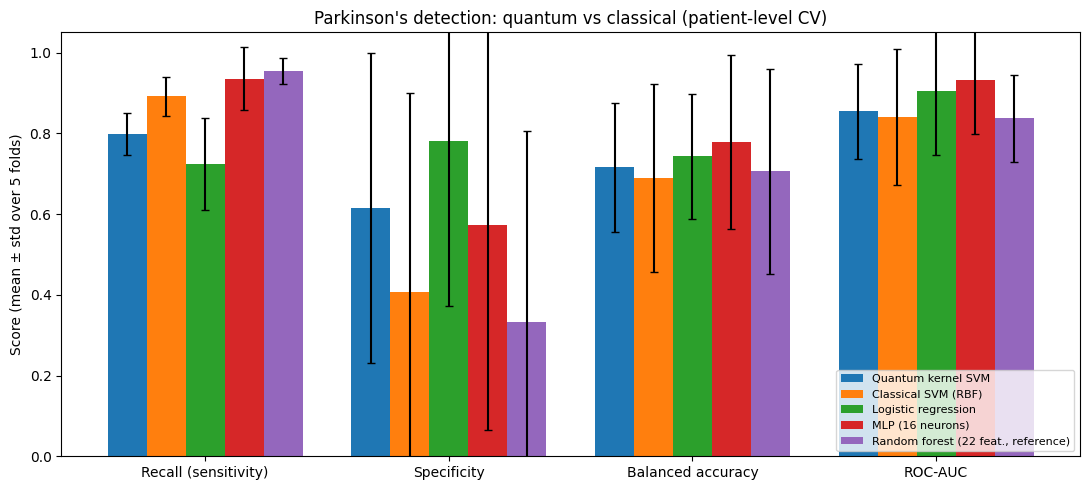

In [25]:
# Bar chart of the key metrics
plot_metrics = ["Recall (sensitivity)", "Specificity", "Balanced accuracy", "ROC-AUC"]
x = np.arange(len(plot_metrics))
w = 0.8 / len(ORDER)

fig, ax = plt.subplots(figsize=(11, 5))
for i, model in enumerate(ORDER):
    ax.bar(x + i * w, mean.loc[model, plot_metrics], w,
           yerr=std.loc[model, plot_metrics], capsize=3, label=model)
ax.set_xticks(x + w * (len(ORDER) - 1) / 2)
ax.set_xticklabels(plot_metrics)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score (mean ± std over 5 folds)")
ax.set_title("Parkinson's detection: quantum vs classical (patient-level CV)")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("figures/main_comparison.png", dpi=200)
plt.show()

## Step 9 — Low-data experiment (the core question)
Medical data is often scarce. We train on only **25%, 50%, 75% and 100% of the training people** (keeping at least one healthy and one Parkinson's person) and always test on the same held-out people.

Each fraction is repeated with 5 random draws per fold. Hyperparameters are the ones chosen in Step 7 for that fold, and feature preprocessing is the fold's preprocessing, so only the amount of training data changes.

In [26]:
FRACTIONS = [0.25, 0.5, 0.75, 1.0]
N_REPEATS = 5
rng = np.random.default_rng(SEED)

def sample_people(y_tr, g_tr, frac):
    # Keep `frac` of the healthy people and `frac` of the Parkinson's people
    chosen = []
    for label in (0, 1):
        people_lab = np.unique(g_tr[y_tr == label])
        k = max(1, int(round(frac * len(people_lab))))
        chosen += list(rng.choice(people_lab, k, replace=False))
    return np.isin(g_tr, chosen)

low_rows = []
for fold, info in enumerate(fold_info):
    y_tr, y_te = y[info["tr"]], y[info["te"]]
    g_tr = groups[info["tr"]]
    S_tr = quantum_states(info["A_tr"], info["q_b"])
    S_te = quantum_states(info["A_te"], info["q_b"])

    for frac in FRACTIONS:
        for rep in range(1 if frac == 1.0 else N_REPEATS):
            mask = sample_people(y_tr, g_tr, frac)
            A_sub, y_sub = info["A_tr"][mask], y_tr[mask]

            m_q = fit_eval_kernel_svm(quantum_kernel(S_tr[mask], S_tr[mask]),
                                      quantum_kernel(S_te, S_tr[mask]), y_sub, y_te, info["q_C"])
            m_c = fit_eval_kernel_svm(rbf_kernel(A_sub, A_sub, gamma=info["c_g"]),
                                      rbf_kernel(info["A_te"], A_sub, gamma=info["c_g"]),
                                      y_sub, y_te, info["c_C"])
            m_l = fit_eval_model(LogisticRegression(C=info["lr_C"], class_weight="balanced", max_iter=5000),
                                 A_sub, info["A_te"], y_sub, y_te)
            n_people = len(np.unique(g_tr[mask]))
            for name, m in [("Quantum kernel SVM", m_q), ("Classical SVM (RBF)", m_c),
                            ("Logistic regression", m_l)]:
                low_rows.append({"Fold": fold + 1, "Fraction": frac, "Train people": n_people,
                                 "Model": name, **m})

low_df = pd.DataFrame(low_rows)
low_df.to_csv("results_low_data.csv", index=False)

low_summary = low_df.groupby(["Fraction", "Model"])[["Balanced accuracy", "ROC-AUC", "Recall (sensitivity)"]].agg(["mean", "std"]).round(3)
low_summary

Balanced accuracy        ROC-AUC         \
                                          mean    std    mean    std   
Fraction Model                                                         
0.25     Classical SVM (RBF)             0.543  0.248   0.668  0.244   
         Logistic regression             0.666  0.186   0.772  0.224   
         Quantum kernel SVM              0.615  0.162   0.738  0.213   
0.50     Classical SVM (RBF)             0.687  0.202   0.725  0.247   
         Logistic regression             0.727  0.167   0.852  0.192   
         Quantum kernel SVM              0.656  0.154   0.818  0.178   
0.75     Classical SVM (RBF)             0.717  0.194   0.822  0.172   
         Logistic regression             0.760  0.150   0.901  0.156   
         Quantum kernel SVM              0.742  0.139   0.849  0.120   
1.00     Classical SVM (RBF)             0.690  0.233   0.841  0.169   
         Logistic regression             0.743  0.156   0.906  0.161   
         Quantum kernel SVM              0.716  0.160   0.854  0.118   

                             Recall (sensitivity)         
                                             mean    std  
Fraction Model                                            
0.25     Classical SVM (RBF)                0.666  0.323  
         Logistic regression                0.734  0.198  
         Quantum kernel SVM                 0.675  0.278  
0.50     Classical SVM (RBF)                0.802  0.205  
         Logistic regression                0.750  0.124  
         Quantum kernel SVM                 0.786  0.174  
0.75     Classical SVM (RBF)                0.827  0.181  
         Logistic regression                0.757  0.091  
         Quantum kernel SVM                 0.814  0.072  
1.00     Classical SVM (RBF)                0.891  0.048  
         Logistic regression                0.724  0.115  
         Quantum kernel SVM                 0.798  0.052

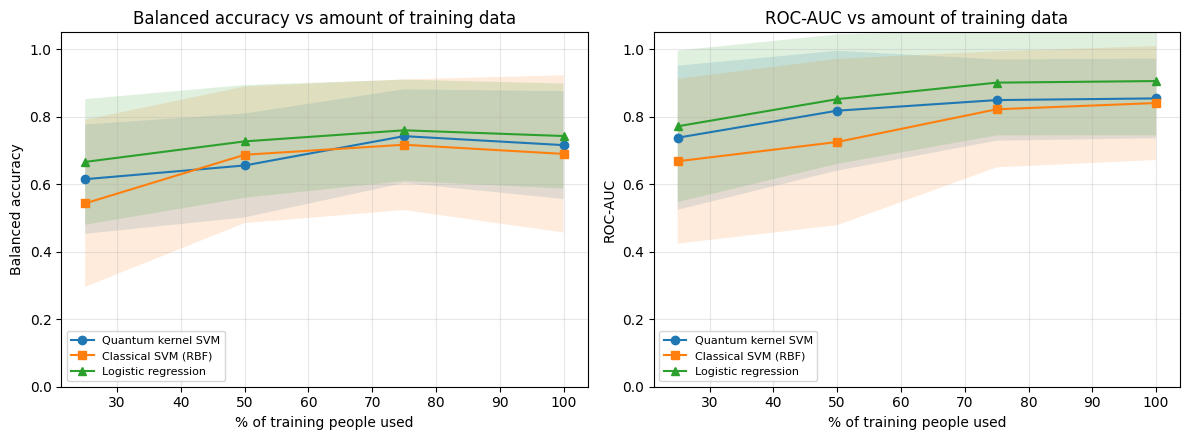

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric in zip(axes, ["Balanced accuracy", "ROC-AUC"]):
    for model, marker in [("Quantum kernel SVM", "o"), ("Classical SVM (RBF)", "s"), ("Logistic regression", "^")]:
        d = low_df[low_df["Model"] == model].groupby("Fraction")[metric]
        mu, sd = d.mean(), d.std()
        ax.plot(mu.index * 100, mu.values, marker=marker, label=model)
        ax.fill_between(mu.index * 100, mu - sd, mu + sd, alpha=0.15)
    ax.set_xlabel("% of training people used")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs amount of training data")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/low_data_experiment.png", dpi=200)
plt.show()

## Step 10 — Look inside the kernels
Each matrix shows the similarity between every pair of recordings (fold 1 training data), **sorted so all healthy recordings come first**. A good kernel shows two bright blocks on the diagonal (healthy look like healthy, Parkinson's like Parkinson's).

**Kernel–target alignment** puts a number on this (higher = the kernel's notion of similarity matches the diagnosis better).

Quantum kernel values: min=0.954, mean=0.993, max=1.000
RBF kernel values:     min=0.007, mean=0.548, max=1.000


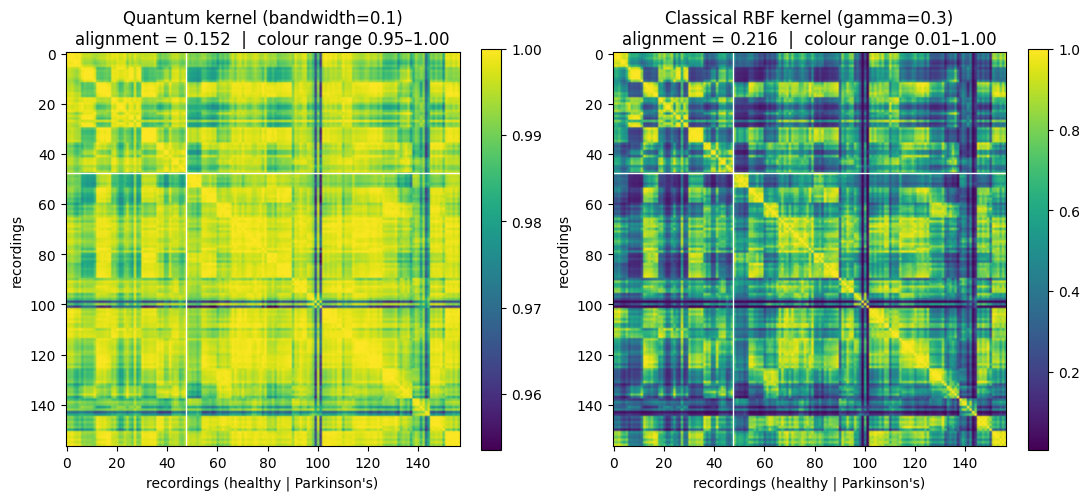

In [37]:
info = fold_info[0]
y_tr0 = y[info["tr"]]
order = np.argsort(y_tr0, kind="stable")
A0 = info["A_tr"][order]
y0 = y_tr0[order]

S0 = quantum_states(A0, info["q_b"])
K_q = quantum_kernel(S0, S0)
K_c = rbf_kernel(A0, A0, gamma=info["c_g"])

def alignment(K, labels):
    t = np.where(labels == 1, 1.0, -1.0)
    T = np.outer(t, t)
    return float((K * T).sum() / (np.linalg.norm(K) * np.linalg.norm(T)))

# Print the real range of similarity values for each kernel
print(f"Quantum kernel values: min={K_q.min():.3f}, mean={K_q.mean():.3f}, max={K_q.max():.3f}")
print(f"RBF kernel values:     min={K_c.min():.3f}, mean={K_c.mean():.3f}, max={K_c.max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
n_healthy = (y0 == 0).sum()
for ax, K, title in [(axes[0], K_q, f"Quantum kernel (bandwidth={info['q_b']})"),
                     (axes[1], K_c, f"Classical RBF kernel (gamma={info['c_g']})")]:
    # FIX: colours stretch from this kernel's own minimum to 1, so structure is visible
    im = ax.imshow(K, cmap="viridis", vmin=K.min(), vmax=1)
    ax.axhline(n_healthy - 0.5, color="white", lw=1)
    ax.axvline(n_healthy - 0.5, color="white", lw=1)
    ax.set_title(f"{title}\nalignment = {alignment(K, y0):.3f}  |  colour range {K.min():.2f}–1.00")
    ax.set_xlabel("recordings (healthy | Parkinson's)")
    ax.set_ylabel("recordings")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig("figures/kernel_matrices.png", dpi=200)
plt.show()

## Step 11 — Conclusions (fill in from your results)
**How to read the results honestly:**
- Compare **Quantum kernel SVM vs Classical SVM (RBF)** first; they are identical except for the kernel, so this is the fair comparison.
- With only ~6 test people per fold, differences smaller than the standard deviation are **not significant**; call them "comparable".
- In the low-data plot, look at the left side (25% of people). If the quantum curve is above or equal to the classical curves there, that supports the small-data argument.
- The random forest uses all 22 features, so it is a reference ceiling, not a like-for-like competitor.

**Limitations to state:**
- Results come from a noiseless **simulator**; real quantum hardware adds noise.
- The dataset is small (31 people), so confidence intervals are wide.
- 4 qubits are easy to simulate classically; this study tests *whether quantum kernels are useful* for this data, not a proof of quantum speed-up.

**Write your findings here:**
- Main result: …
- Low-data result: …
- What the kernel matrices show: …